<a href="https://colab.research.google.com/github/mcamilh03/Taller-gr-ficos-Publicacion-Maria-Dominguez-Maria-Loaiza-Estefania-Gamboa/blob/main/Taller_Graficos_Publicacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Estefania Gamboa, Maria Jose Dominguez & Maria Camila Loaiza

# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts** para Gemini, en el mismo Colab.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (1).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [ ]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

,total
producto,
Cuaderno,20712345
Block de notas,14292347
Resma carta,13133570
Marcador,10020786
Colores x12,9419625


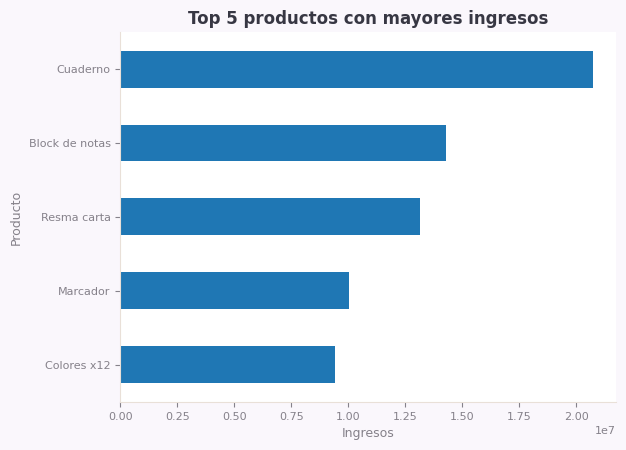

In [ ]:
# Ejercicio 1
# Erefania Gamboa, Maria Jose Domingiez, Maria Camila Loaiza
top_productos = df.groupby("producto")["total"].sum()

top_productos = top_productos.sort_values(ascending=False)

top_productos = top_productos.head(5)

display(top_productos)

top_productos.sort_values().plot.barh()

plt.title("Top 5 productos con mayores ingresos")
plt.xlabel("Ingresos")
plt.ylabel("Producto")
plt.show()

### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

ciudad,Bogotá,Medellín
mes,,
1,4815405,3504905
2,3037200,2262080
3,3629385,1342665
4,3117990,1107910
5,3937775,3164730
6,1631810,2848235
7,2781218,2771377
8,3706217,4092446
9,2245001,969551


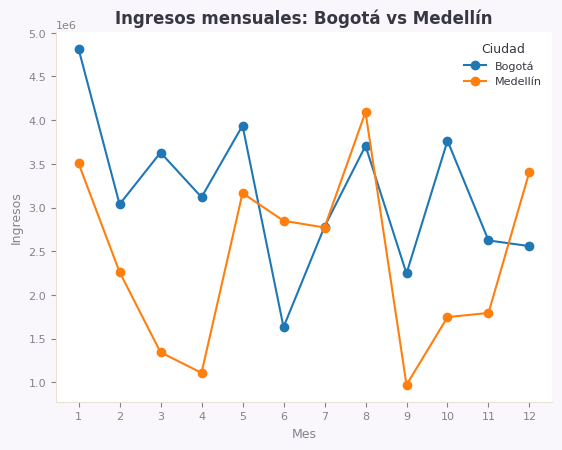

In [ ]:
# Ejercicio 2
# Seleccionar solo Bogotá y Medellín
ventas_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]

# Crear tabla dinámica
ing_mes_ciudad = ventas_ciudades.pivot_table(
    index="mes",
    columns="ciudad",
    values="total",
    aggfunc="sum"
)

# Mostrar la tabla
display(ing_mes_ciudad)

# Crear gráfico de líneas
ing_mes_ciudad.plot.line(marker="o")

plt.title("Ingresos mensuales: Bogotá vs Medellín")
plt.xlabel("Mes")
plt.ylabel("Ingresos")
plt.xticks(range(1, 13))
plt.legend(title="Ciudad")
plt.show()

### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

,total
canal,
Online,22887574
Telefónico,61450716
Tienda,34329722


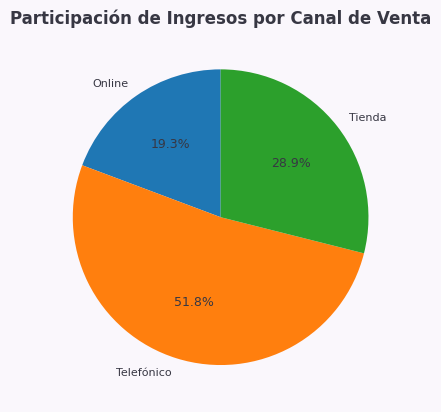

In [ ]:
# Ejercicio 3
# Calcular ingresos totales por canal
ing_canal = df.groupby("canal")["total"].sum()

# Mostrar la tabla
display(ing_canal)

# Crear gráfico de pie con porcentajes
ing_canal.plot.pie(
    autopct="%1.1f%%",
    startangle=90,
    colors=["#1f77b4", "#ff7f0e", "#2ca02c"]
)

plt.title("Participación de Ingresos por Canal de Venta")
plt.ylabel("")  # Remueve el nombre de la columna en el eje Y
plt.show()

### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

categoria,Arte,Corrección,Escritura,Organización,Papel
segmento,,,,,
Corporativo,2.807775,5.399568,30.237581,23.326134,38.228942
Mayorista,5.623472,12.224939,54.034230,5.623472,22.493888
Minorista,12.056738,12.765957,55.762411,4.255319,15.159574


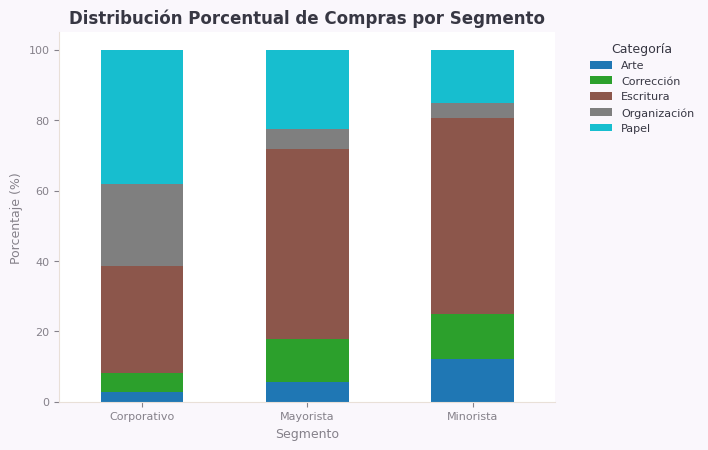

In [ ]:
# Ejercicio 4
# Contar ventas por segmento y categoría normalizando por fila
tabla_seg_cat = pd.crosstab(
    df["segmento"],
    df["categoria"],
    normalize="index"
) * 100

# Mostrar la tabla
display(tabla_seg_cat)

# Graficar barras apiladas
tabla_seg_cat.plot.bar(stacked=True, colormap="tab10")

plt.title("Distribución Porcentual de Compras por Segmento")
plt.xlabel("Segmento")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.legend(title="Categoría", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

,vendedor,ciudad,n_ventas,ticket_prom
0,Andrés Rojas,Medellín,192,60729.104167
1,Camilo Pardo,Bogotá,210,54276.595238
2,Daniela Ríos,Bogotá,130,62903.423077
3,Esteban Uribe,Medellín,94,61833.978723
4,Isabela Mora,Bucaramanga,108,65873.037037


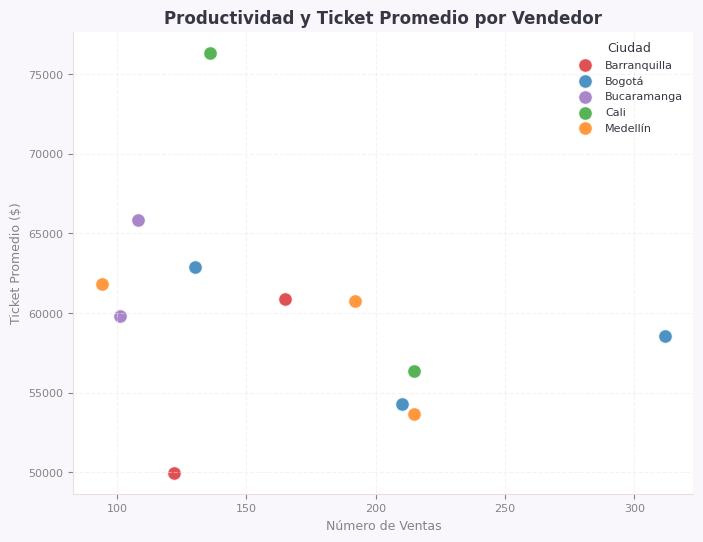

In [ ]:
# Ejercicio 5
# Agrupar por vendedor y ciudad para calcular n_ventas y ticket_prom
vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()

# Mostrar la tabla
display(vend.head())

# Gráfico de dispersión con un color por ciudad
colores_ciudad = {
    "Bogotá": "#1f77b4",
    "Medellín": "#ff7f0e",
    "Cali": "#2ca02c",
    "Barranquilla": "#d62728",
    "Bucaramanga": "#9467bd"
}

plt.figure(figsize=(8, 6))
for ciudad, grupo in vend.groupby("ciudad"):
    plt.scatter(
        grupo["n_ventas"],
        grupo["ticket_prom"],
        label=ciudad,
        color=colores_ciudad[ciudad],
        s=100,
        alpha=0.8,
        edgecolors="w"
    )

plt.title("Productividad y Ticket Promedio por Vendedor")
plt.xlabel("Número de Ventas")
plt.ylabel("Ticket Promedio ($)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Ciudad")
plt.show()

### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

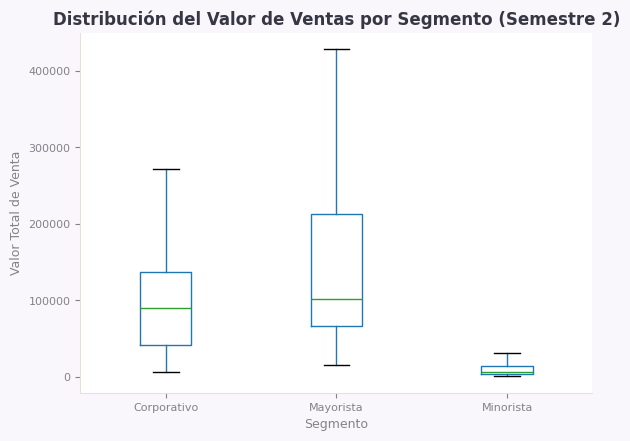

In [ ]:
# Ejercicio 6
# Seleccionar ventas del segundo semestre (meses 7 a 12)
sem2 = df[df["mes"].between(7, 12)]

# Diagrama de cajas de total por segmento sin atípicos
sem2.boxplot(column="total", by="segmento", showfliers=False, grid=False)

plt.title("Distribución del Valor de Ventas por Segmento (Semestre 2)")
plt.suptitle("")  # Remueve el título automático de pandas
plt.xlabel("Segmento")
plt.ylabel("Valor Total de Venta")
plt.show()

---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [ ]:
%run -i figura_base.py

/content/figura_base.py:119: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


In [ ]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt y Gemini reescribe el código** de tu figura para que se vea profesional, casi como un dashboard.


### Herramientas *(ya están hechas)*
Ejecuta esta celda. Define dos funciones:

- **`embellecer(prompt, nombre)`**: envía tu prompt **junto con tu código de `figura_base.py`**, ejecuta el código nuevo que devuelve Gemini y muestra la figura. Cada versión queda guardada en `VERSIONES[nombre]`.
- **`mostrar(nombre)`**: vuelve a dibujar una versión guardada.

In [ ]:
import re

VERSIONES = {}      # aquí se guarda el código de cada versión ("v1", "v2", ...)

REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual (puedes recalcular las tablas con el mismo código);
  cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def extraer_codigo(texto):
    """Devuelve el contenido del primer bloque de código ``` de la respuesta."""
    bloque = re.search(r"```(?:python)?\s*\n(.*?)```", texto, re.S)
    return bloque.group(1) if bloque else texto


def dibujar(codigo):
    """Ejecuta el código de una figura y la muestra."""
    import numpy as np
    plt.close("all")
    espacio = {"df": df, "pd": pd, "plt": plt, "np": np}
    exec(codigo, espacio)
    figura = espacio["fig"]
    display(figura)
    plt.close(figura)


def embellecer(prompt, nombre, modelo="gemini-flash-latest"):
    """Gemini reescribe tu figura según tu prompt; se ejecuta, se muestra y se guarda en VERSIONES."""
    codigo_actual = open("figura_base.py", encoding="utf-8").read()
    contenido = f"{prompt}\n\nEste es mi código actual:\n```python\n{codigo_actual}\n```{REGLAS_FIGURA}"
    respuesta = client.models.generate_content(model=modelo, contents=contenido)
    codigo = extraer_codigo(respuesta.text)
    try:
        dibujar(codigo)
    except Exception as e:
        print("❌ El código de Gemini falló:", type(e).__name__, e)
        print("Copia ese error en tu siguiente prompt y pídele que lo corrija.")
        return
    VERSIONES[nombre] = codigo
    print(f"✔ Versión '{nombre}' guardada")


def mostrar(nombre):
    """Vuelve a dibujar una versión guardada."""
    dibujar(VERSIONES[nombre])

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

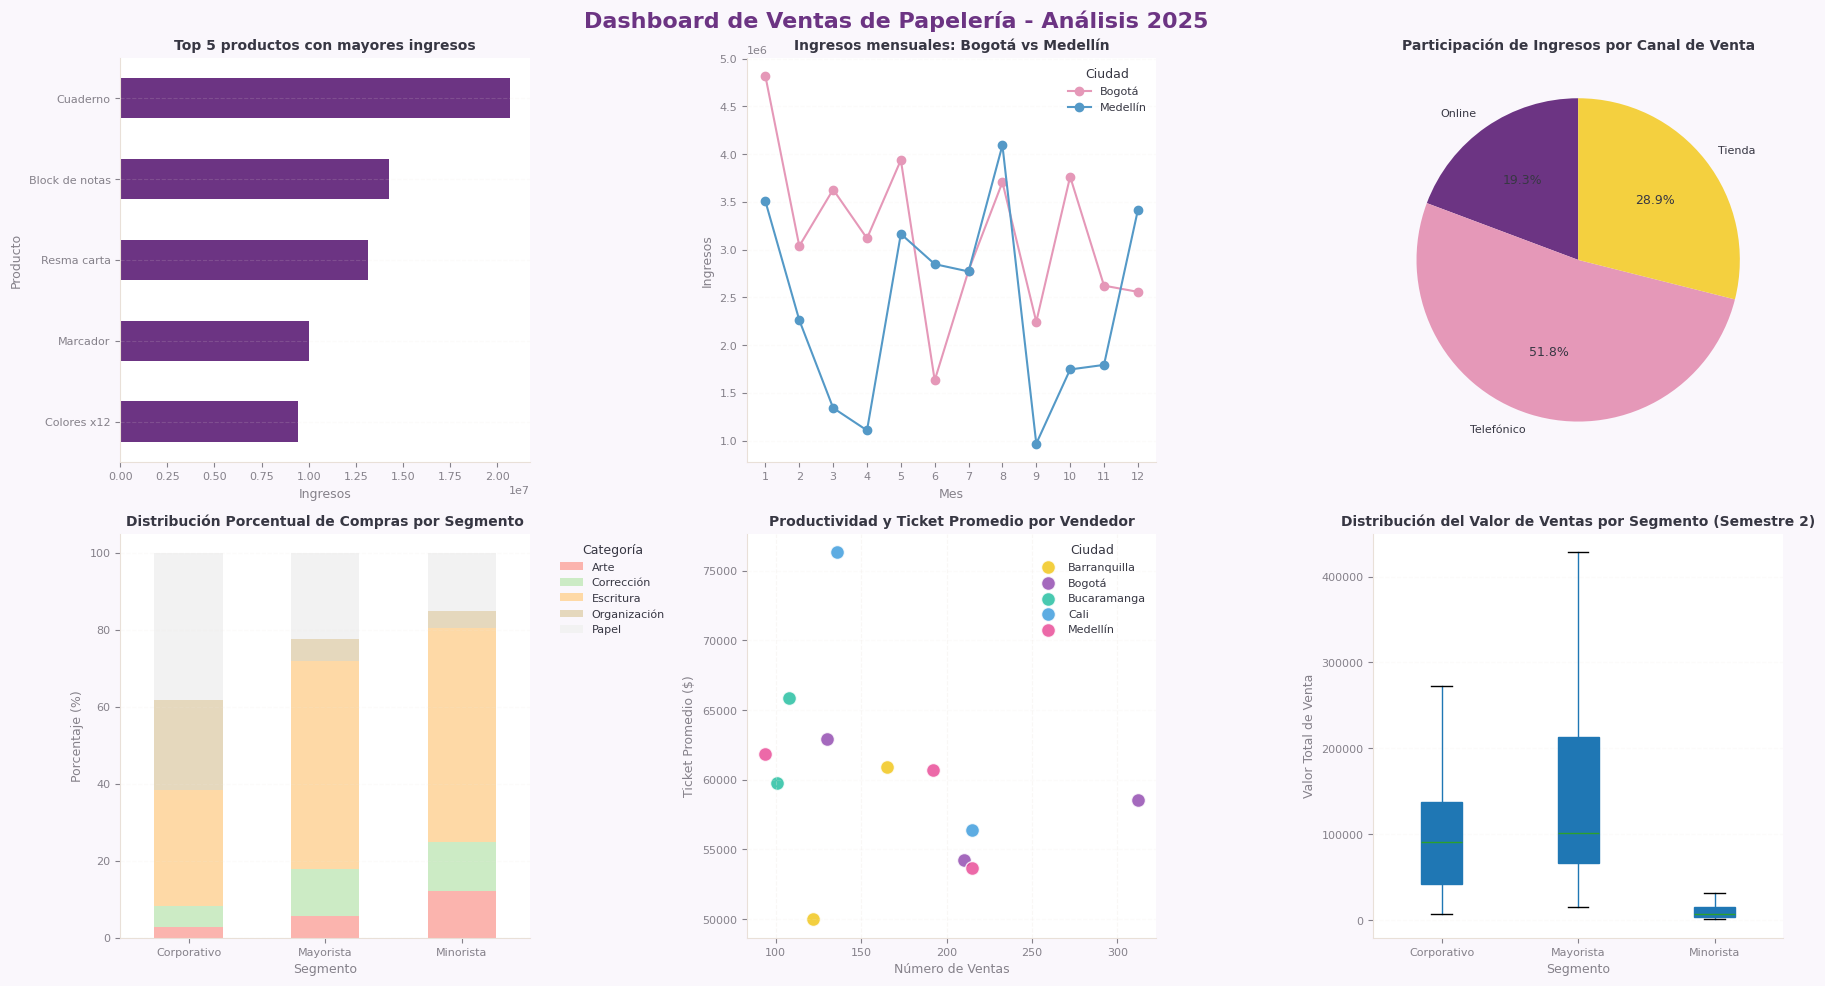

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


import pandas as pd
import matplotlib.pyplot as plt

# Paleta de colores nueva
colores = {
    "morado": "#6C3483",
    "lila": "#AF7AC5",
    "rosado": "#E598B8",
    "rosa_claro": "#F5B7B1",
    "amarillo": "#F4D03F",
    "azul": "#5499C7",
    "verde": "#76D7C4",
    "fondo": "#FAF7FC"
}

# Configuración visual
plt.rcParams["figure.facecolor"] = colores["fondo"]
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.titleweight"] = "bold"

# Crear figura y subplots
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# 1. Top 5 Productos
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)

top_productos.sort_values().plot.barh(
    ax=axs[0, 0],
    color=colores["morado"]
)

axs[0, 0].set_title("Top 5 productos con mayores ingresos")
axs[0, 0].set_xlabel("Ingresos")
axs[0, 0].set_ylabel("Producto")

# 2. Bogotá vs Medellín
ventas_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]

ing_mes_ciudad = ventas_ciudades.pivot_table(
    index="mes", columns="ciudad", values="total", aggfunc="sum"
)

ing_mes_ciudad.plot.line(
    marker="o",
    ax=axs[0, 1],
    color=[colores["rosado"], colores["azul"]]
)

axs[0, 1].set_title("Ingresos mensuales: Bogotá vs Medellín")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].legend(title="Ciudad")

# 3. Ingresos por Canal
ing_canal = df.groupby("canal")["total"].sum()

ing_canal.plot.pie(
    autopct="%1.1f%%",
    startangle=90,
    colors=[
        colores["morado"],
        colores["rosado"],
        colores["amarillo"]
    ],
    ax=axs[0, 2]
)

axs[0, 2].set_title("Participación de Ingresos por Canal de Venta")
axs[0, 2].set_ylabel("")

# 4. Distribución por Segmento
tabla_seg_cat = pd.crosstab(
    df["segmento"], df["categoria"], normalize="index"
) * 100

tabla_seg_cat.plot.bar(
    stacked=True,
    colormap="Pastel1",
    ax=axs[1, 0]
)

axs[1, 0].set_title("Distribución Porcentual de Compras por Segmento")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].set_xticklabels(tabla_seg_cat.index, rotation=0)
axs[1, 0].legend(title="Categoría", bbox_to_anchor=(1.05, 1), loc="upper left")

# 5. Productividad de Vendedores
vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()

colores_ciudad = {
    "Bogotá": "#8E44AD",
    "Medellín": "#E84393",
    "Cali": "#3498DB",
    "Barranquilla": "#F1C40F",
    "Bucaramanga": "#1ABC9C"
}

for ciudad, grupo in vend.groupby("ciudad"):
    axs[1, 1].scatter(
        grupo["n_ventas"],
        grupo["ticket_prom"],
        label=ciudad,
        color=colores_ciudad.get(ciudad, "#999999"),
        s=100,
        alpha=0.8,
        edgecolors="white"
    )

axs[1, 1].set_title("Productividad y Ticket Promedio por Vendedor")
axs[1, 1].set_xlabel("Número de Ventas")
axs[1, 1].set_ylabel("Ticket Promedio ($)")
axs[1, 1].grid(True, linestyle="--", alpha=0.3)
axs[1, 1].legend(title="Ciudad")

# 6. Boxplot Semestre 2
sem2 = df[df["mes"].between(7, 12)]

sem2.boxplot(
    column="total",
    by="segmento",
    showfliers=False,
    grid=False,
    ax=axs[1, 2],
    patch_artist=True
)

axs[1, 2].set_title("Distribución del Valor de Ventas por Segmento (Semestre 2)")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor Total de Venta")

# Aplicar colores y limpieza visual
for ax in axs.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.15, linestyle="--")

    ax.title.set_fontsize(10)

fig.suptitle(
    "Dashboard de Ventas de Papelería - Análisis 2025",
    fontsize=16,
    fontweight="bold",
    color=colores["morado"]
)

plt.tight_layout()
plt.show()


### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (por ejemplo: otra paleta, letras más grandes, anotar el valor máximo del gráfico de líneas, cambiar el pie por una dona…). Es la **iteración de prompts** que vimos en clase.

/tmp/ipykernel_1943/753307565.py:349: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  resultado_box = axs[1, 2].boxplot(


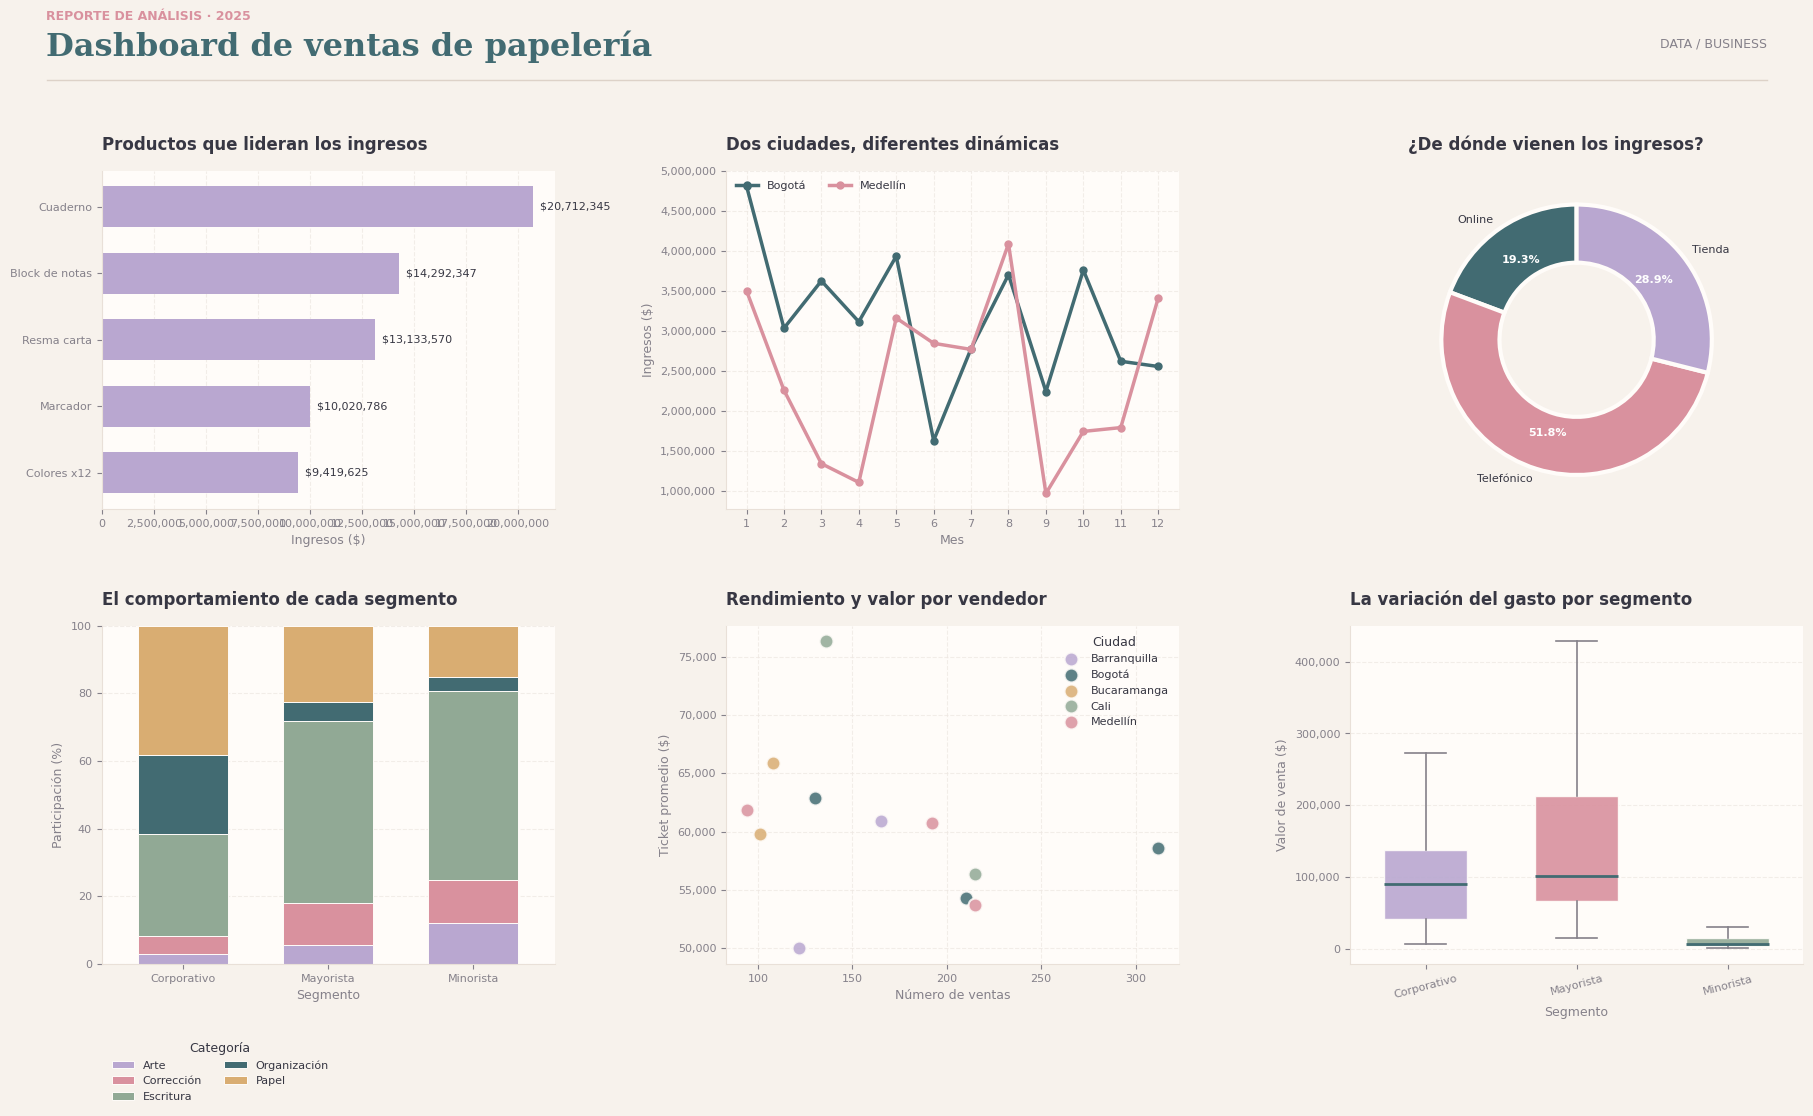

Dashboard versión 2 generado exitosamente.
Archivo guardado: dashboard_ventas_v2.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import StrMethodFormatter

# ==========================================
# 1. PALETA DE COLORES - SOFT EDITORIAL
# ==========================================

CREMA = "#F7F2EC"
BLANCO = "#FFFCF9"
LAVANDA = "#B9A7D0"
ROSA = "#D9919E"
SALVIA = "#91A995"
PETROLEO = "#426B72"
OCRE = "#D9AD72"
TEXTO = "#373743"
GRIS = "#85818A"

paleta = [
    LAVANDA,
    ROSA,
    SALVIA,
    PETROLEO,
    OCRE,
    "#A7B9CC",
    "#C5A6A0"
]

# ==========================================
# 2. TIPOGRAFÍA Y ESTILO GENERAL
# ==========================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "text.color": TEXTO,

    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": TEXTO,

    "axes.labelsize": 9,
    "axes.labelcolor": GRIS,

    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.color": GRIS,
    "ytick.color": GRIS,

    "axes.facecolor": BLANCO,
    "figure.facecolor": CREMA,

    "axes.edgecolor": "#E9E0D8",
    "axes.spines.top": False,
    "axes.spines.right": False,

    "grid.color": "#EDE7E1",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    "legend.fontsize": 8,
    "legend.frameon": False
})

# ==========================================
# 3. CREACIÓN DEL DASHBOARD
# ==========================================

fig, axs = plt.subplots(
    2, 3,
    figsize=(20, 12)
)

fig.patch.set_facecolor(CREMA)

# Fondo individual de cada gráfico
for ax in axs.flat:
    ax.set_facecolor(BLANCO)
    ax.title.set_fontfamily("DejaVu Serif")
    ax.title.set_fontsize(12)
    ax.title.set_fontweight("bold")
    ax.title.set_color(PETROLEO)
    ax.set_axisbelow(True)

# ==========================================
# 4. TOP 5 PRODUCTOS
# ==========================================

top_productos = (
    df.groupby("producto")["total"]
    .sum()
    .nlargest(5)
    .sort_values()
)

barras = axs[0, 0].barh(
    top_productos.index,
    top_productos.values,
    color=LAVANDA,
    height=0.62,
    edgecolor="none"
)

axs[0, 0].set_title(
    "Productos que lideran los ingresos",
    loc="left",
    pad=15
)

axs[0, 0].set_xlabel("Ingresos ($)")
axs[0, 0].xaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

axs[0, 0].grid(axis="x")

# Etiquetas de valores
for barra in barras:
    valor = barra.get_width()
    axs[0, 0].text(
        valor,
        barra.get_y() + barra.get_height()/2,
        f"  ${valor:,.0f}",
        va="center",
        fontsize=8,
        color=TEXTO
    )

# ==========================================
# 5. BOGOTÁ VS MEDELLÍN
# ==========================================

ventas_ciudades = df[
    df["ciudad"].isin(["Bogotá", "Medellín"])
]

ing_mes_ciudad = ventas_ciudades.pivot_table(
    index="mes",
    columns="ciudad",
    values="total",
    aggfunc="sum"
).reindex(range(1, 13))

colores_lineas = {
    "Bogotá": PETROLEO,
    "Medellín": ROSA
}

for ciudad in ing_mes_ciudad.columns:
    axs[0, 1].plot(
        ing_mes_ciudad.index,
        ing_mes_ciudad[ciudad],
        marker="o",
        markersize=5,
        linewidth=2.5,
        color=colores_lineas[ciudad],
        label=ciudad
    )

axs[0, 1].set_title(
    "Dos ciudades, diferentes dinámicas",
    loc="left",
    pad=15
)

axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].set_xticks(range(1, 13))

axs[0, 1].yaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

axs[0, 1].legend(
    loc="upper left",
    ncol=2
)

axs[0, 1].grid(True)

# ==========================================
# 6. INGRESOS POR CANAL
# ==========================================

ing_canal = df.groupby("canal")["total"].sum()

colores_pie = [
    PETROLEO,
    ROSA,
    LAVANDA,
    SALVIA,
    OCRE,
    "#A7B9CC"
]

wedges, texts, autotexts = axs[0, 2].pie(
    ing_canal,
    labels=ing_canal.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colores_pie[:len(ing_canal)],
    pctdistance=0.72,
    labeldistance=1.08,
    wedgeprops={
        "width": 0.43,
        "edgecolor": BLANCO,
        "linewidth": 3
    },
    textprops={
        "fontsize": 8,
        "color": TEXTO
    }
)

for texto in autotexts:
    texto.set_color("white")
    texto.set_fontweight("bold")
    texto.set_fontsize(8)

axs[0, 2].set_title(
    "¿De dónde vienen los ingresos?",
    loc="left",
    pad=15
)

# ==========================================
# 7. DISTRIBUCIÓN POR SEGMENTO
# ==========================================

tabla_seg_cat = pd.crosstab(
    df["segmento"],
    df["categoria"],
    normalize="index"
) * 100

tabla_seg_cat.plot(
    kind="bar",
    stacked=True,
    ax=axs[1, 0],
    color=paleta[:len(tabla_seg_cat.columns)],
    width=0.62,
    edgecolor=BLANCO,
    linewidth=0.7
)

axs[1, 0].set_title(
    "El comportamiento de cada segmento",
    loc="left",
    pad=15
)

axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Participación (%)")
axs[1, 0].set_ylim(0, 100)

axs[1, 0].set_xticklabels(
    tabla_seg_cat.index,
    rotation=0
)

axs[1, 0].legend(
    title="Categoría",
    loc="upper left",
    bbox_to_anchor=(0, -0.20),
    ncol=2
)

axs[1, 0].grid(axis="y")

# ==========================================
# 8. PRODUCTIVIDAD DE VENDEDORES
# ==========================================

vend = df.groupby(
    ["vendedor", "ciudad"]
).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()

colores_ciudad = {
    "Bogotá": PETROLEO,
    "Medellín": ROSA,
    "Cali": SALVIA,
    "Barranquilla": LAVANDA,
    "Bucaramanga": OCRE
}

for ciudad, grupo in vend.groupby("ciudad"):
    axs[1, 1].scatter(
        grupo["n_ventas"],
        grupo["ticket_prom"],
        label=ciudad,
        color=colores_ciudad.get(ciudad, GRIS),
        s=100,
        alpha=0.85,
        edgecolors=BLANCO,
        linewidth=1.5
    )

axs[1, 1].set_title(
    "Rendimiento y valor por vendedor",
    loc="left",
    pad=15
)

axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")

axs[1, 1].yaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

axs[1, 1].legend(
    title="Ciudad",
    loc="best"
)

axs[1, 1].grid(True)

# ==========================================
# 9. BOXPLOT - SEGUNDO SEMESTRE
# ==========================================

sem2 = df[df["mes"].between(7, 12)]

datos_box = [
    grupo["total"].dropna().values
    for _, grupo in sem2.groupby("segmento", sort=True)
]

nombres_segmentos = [
    nombre
    for nombre, grupo in sem2.groupby("segmento", sort=True)
    if grupo["total"].notna().any()
]

# Solo se representan segmentos con datos
datos_box = [
    sem2.loc[
        sem2["segmento"] == nombre,
        "total"
    ].dropna().values
    for nombre in nombres_segmentos
]

if datos_box:
    resultado_box = axs[1, 2].boxplot(
        datos_box,
        patch_artist=True,
        labels=nombres_segmentos,
        showfliers=False,
        widths=0.55,
        medianprops={
            "color": PETROLEO,
            "linewidth": 2
        },
        whiskerprops={
            "color": GRIS,
            "linewidth": 1.2
        },
        capprops={
            "color": GRIS,
            "linewidth": 1.2
        }
    )

    for i, caja in enumerate(resultado_box["boxes"]):
        caja.set_facecolor(paleta[i % len(paleta)])
        caja.set_edgecolor(BLANCO)
        caja.set_alpha(0.9)

axs[1, 2].set_title(
    "La variación del gasto por segmento",
    loc="left",
    pad=15
)

axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor de venta ($)")

axs[1, 2].yaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

axs[1, 2].tick_params(axis="x", rotation=15)
axs[1, 2].grid(axis="y")

# ==========================================
# 10. IDENTIDAD VISUAL Y ENCABEZADO
# ==========================================

fig.text(
    0.07, 0.975,
    "REPORTE DE ANÁLISIS · 2025",
    fontsize=9,
    color=ROSA,
    fontweight="bold"
)

fig.text(
    0.07, 0.945,
    "Dashboard de ventas de papelería",
    fontsize=23,
    fontfamily="DejaVu Serif",
    fontweight="bold",
    color=PETROLEO
)

fig.text(
    0.93, 0.952,
    "DATA / BUSINESS",
    fontsize=9,
    color=GRIS,
    ha="right"
)

# Línea decorativa
fig.add_artist(
    plt.Line2D(
        [0.07, 0.93],
        [0.925, 0.925],
        transform=fig.transFigure,
        color="#DDD2C8",
        linewidth=1
    )
)

# ==========================================
# 11. AJUSTES FINALES
# ==========================================

plt.tight_layout(
    rect=[0.045, 0.045, 0.955, 0.89],
    h_pad=3.5,
    w_pad=2.5
)

# Guardar dashboard
fig.savefig(
    "dashboard_ventas_v2.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=CREMA
)

plt.show()

print("Dashboard versión 2 generado exitosamente.")
print("Archivo guardado: dashboard_ventas_v2.png")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`) y ejecútalo con el nombre `"v3"`. Tendrás tres versiones para comparar.

In [ ]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# embellecer(prompt_v3, "v3")

In [ ]:
# ✅ Verificación
assert len(VERSIONES) >= 2, "Debes tener al menos dos versiones de tu figura (v1 y v2)"
print("Versiones guardadas:", list(VERSIONES), "· Parte C correcta ✔")

AssertionError: Debes tener al menos dos versiones de tu figura (v1 y v2)

---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [ ]:
figura_elegida = "v2"      # cambia por "v1", "v2" o "v3"

# 1. Ciudad con mayores ingresos
ing_ciudad = df.groupby("ciudad")["total"].sum()
ciudad_top = ing_ciudad.idxmax()
porcentaje_ciudad = (ing_ciudad.max() / ing_ciudad.sum()) * 100

# 2. Producto con mayores ingresos
ing_producto = df.groupby("producto")["total"].sum()
producto_top = ing_producto.idxmax()
porcentaje_producto = (ing_producto.max() / ing_producto.sum()) * 100

# 3. Canal de venta más importante
ing_canal = df.groupby("canal")["total"].sum()
canal_top = ing_canal.idxmax()
porcentaje_canal = (ing_canal.max() / ing_canal.sum()) * 100

# Ahora guardamos los tres hallazgos finales calculados dinámicamente
hallazgos = [
    f"{ciudad_top} concentra el {porcentaje_ciudad:.1f}% de los ingresos totales de la papelería.",
    f"{producto_top} es el producto líder, con el {porcentaje_producto:.1f}% de los ingresos de la cadena.",
    f"El canal {canal_top} representa el {porcentaje_canal:.1f}% de las ventas totales de la empresa."
]

# Mostrar hallazgos en pantalla
print("HALLAZGOS PRINCIPALES")
print("-" * 50)
for i, h in enumerate(hallazgos, 1):
    print(f"{i}. {h}")

HALLAZGOS PRINCIPALES
--------------------------------------------------
1. Bogotá concentra el 31.9% de los ingresos totales de la papelería.
2. Cuaderno es el producto líder, con el 17.5% de los ingresos de la cadena.
3. El canal Telefónico representa el 51.8% de las ventas totales de la empresa.


In [ ]:
# ✅ Verificación
assert figura_elegida in VERSIONES, f"No existe la versión {figura_elegida}: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

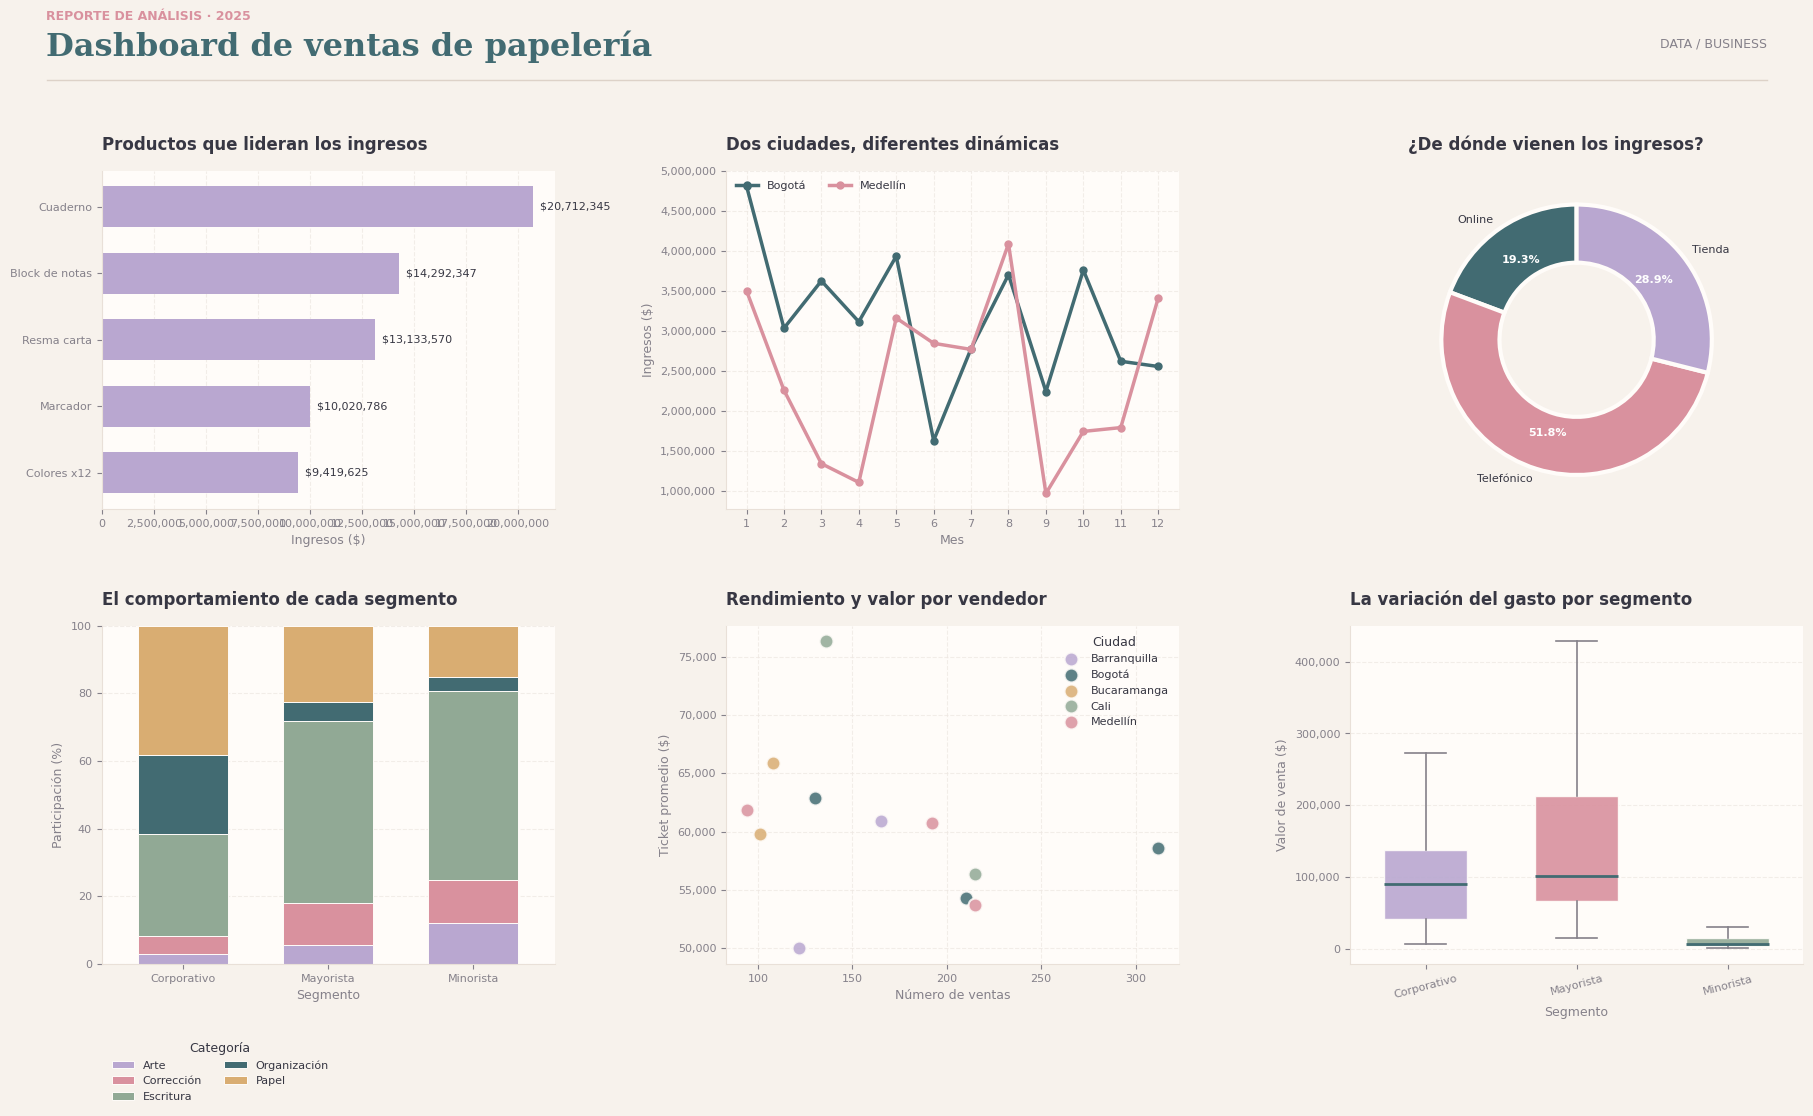

Hallazgos:
• Bogotá concentra el 31.9% de los ingresos totales de la papelería.
• Cuaderno es el producto líder, con el 17.5% de los ingresos de la cadena.
• El canal Telefónico representa el 51.8% de las ventas totales de la empresa.


In [ ]:
# Sobrescribimos figura_base.py con el diseño del Ejercicio 9 (celda c35)
codigo_favorito = """
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import StrMethodFormatter

CREMA = "#F7F2EC"
BLANCO = "#FFFCF9"
LAVANDA = "#B9A7D0"
ROSA = "#D9919E"
SALVIA = "#91A995"
PETROLEO = "#426B72"
OCRE = "#D9AD72"
TEXTO = "#373743"
GRIS = "#85818A"

paleta = [LAVANDA, ROSA, SALVIA, PETROLEO, OCRE, "#A7B9CC", "#C5A6A0"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "text.color": TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": TEXTO,
    "axes.labelsize": 9,
    "axes.labelcolor": GRIS,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.facecolor": BLANCO,
    "figure.facecolor": CREMA,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#EDE7E1",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "legend.fontsize": 8,
    "legend.frameon": False
})

fig, axs = plt.subplots(2, 3, figsize=(20, 12))
fig.patch.set_facecolor(CREMA)

for ax in axs.flat:
    ax.set_facecolor(BLANCO)
    ax.title.set_fontfamily("DejaVu Serif")
    ax.title.set_fontsize(12)
    ax.title.set_fontweight("bold")
    ax.title.set_color(PETROLEO)
    ax.set_axisbelow(True)

# 1. TOP 5 PRODUCTOS
top_productos = df.groupby("producto")["total"].sum().nlargest(5).sort_values()
barras = axs[0, 0].barh(top_productos.index, top_productos.values, color=LAVANDA, height=0.62, edgecolor="none")
axs[0, 0].set_title("Productos que lideran los ingresos", loc="left", pad=15)
axs[0, 0].set_xlabel("Ingresos ($)")
axs[0, 0].xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axs[0, 0].grid(axis="x")
for barra in barras:
    valor = barra.get_width()
    axs[0, 0].text(valor, barra.get_y() + barra.get_height()/2, f"  ${valor:,.0f}", va="center", fontsize=8, color=TEXTO)

# 2. BOGOTÁ VS MEDELLÍN
ventas_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = ventas_ciudades.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum").reindex(range(1, 13))
colores_lineas = {"Bogotá": PETROLEO, "Medellín": ROSA}
for ciudad in ing_mes_ciudad.columns:
    axs[0, 1].plot(ing_mes_ciudad.index, ing_mes_ciudad[ciudad], marker="o", markersize=5, linewidth=2.5, color=colores_lineas[ciudad], label=ciudad)
axs[0, 1].set_title("Dos ciudades, diferentes dinámicas", loc="left", pad=15)
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axs[0, 1].legend(loc="upper left", ncol=2)
axs[0, 1].grid(True)

# 3. INGRESOS POR CANAL
ing_canal = df.groupby("canal")["total"].sum()
wedges, texts, autotexts = axs[0, 2].pie(
    ing_canal, labels=ing_canal.index, autopct="%1.1f%%", startangle=90,
    colors=[PETROLEO, ROSA, LAVANDA], pctdistance=0.72, labeldistance=1.08,
    wedgeprops={"width": 0.43, "edgecolor": BLANCO, "linewidth": 3},
    textprops={"fontsize": 8, "color": TEXTO}
)
for texto in autotexts:
    texto.set_color("white")
    texto.set_fontweight("bold")
    texto.set_fontsize(8)
axs[0, 2].set_title("¿De dónde vienen los ingresos?", loc="left", pad=15)

# 4. DISTRIBUCIÓN POR SEGMENTO
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot(kind="bar", stacked=True, ax=axs[1, 0], color=paleta[:len(tabla_seg_cat.columns)], width=0.62, edgecolor=BLANCO, linewidth=0.7)
axs[1, 0].set_title("El comportamiento de cada segmento", loc="left", pad=15)
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Participación (%)")
axs[1, 0].set_ylim(0, 100)
axs[1, 0].set_xticklabels(tabla_seg_cat.index, rotation=0)
axs[1, 0].legend(title="Categoría", loc="upper left", bbox_to_anchor=(0, -0.20), ncol=2)
axs[1, 0].grid(axis="y")

# 5. PRODUCTIVIDAD DE VENDEDORES
vend = df.groupby(["vendedor", "ciudad"]).agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean")).reset_index()
colores_ciudad = {"Bogotá": PETROLEO, "Medellín": ROSA, "Cali": SALVIA, "Barranquilla": LAVANDA, "Bucaramanga": OCRE}
for ciudad, grupo in vend.groupby("ciudad"):
    axs[1, 1].scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad, color=colores_ciudad.get(ciudad, GRIS), s=100, alpha=0.85, edgecolors=BLANCO, linewidth=1.5)
axs[1, 1].set_title("Rendimiento y valor por vendedor", loc="left", pad=15)
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axs[1, 1].legend(title="Ciudad", loc="best")
axs[1, 1].grid(True)

# 6. BOXPLOT - SEGUNDO SEMESTRE
sem2 = df[df["mes"].between(7, 12)]
datos_box = [sem2.loc[sem2["segmento"] == nombre, "total"].dropna().values for nombre in ["Corporativo", "Mayorista", "Minorista"]]
resultado_box = axs[1, 2].boxplot(datos_box, patch_artist=True, labels=["Corporativo", "Mayorista", "Minorista"], showfliers=False, widths=0.55, medianprops={"color": PETROLEO, "linewidth": 2}, whiskerprops={"color": GRIS, "linewidth": 1.2}, capprops={"color": GRIS, "linewidth": 1.2})
for i, caja in enumerate(resultado_box["boxes"]):
    caja.set_facecolor(paleta[i % len(paleta)])
    caja.set_edgecolor(BLANCO)
    caja.set_alpha(0.9)
axs[1, 2].set_title("La variación del gasto por segmento", loc="left", pad=15)
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor de venta ($)")
axs[1, 2].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axs[1, 2].tick_params(axis="x", rotation=15)
axs[1, 2].grid(axis="y")

# IDENTIDAD VISUAL Y ENCABEZADO
fig.text(0.07, 0.975, "REPORTE DE ANÁLISIS · 2025", fontsize=9, color=ROSA, fontweight="bold")
fig.text(0.07, 0.945, "Dashboard de ventas de papelería", fontsize=23, fontfamily="DejaVu Serif", fontweight="bold", color=PETROLEO)
fig.text(0.93, 0.952, "DATA / BUSINESS", fontsize=9, color=GRIS, ha="right")
fig.add_artist(plt.Line2D([0.07, 0.93], [0.925, 0.925], transform=fig.transFigure, color="#DDD2C8", linewidth=1))

plt.tight_layout(rect=[0.045, 0.045, 0.955, 0.89], h_pad=3.5, w_pad=2.5)
"""

# Guardar el código del ejercicio 9 en figura_base.py
with open("figura_base.py", "w", encoding="utf-8") as f:
    f.write(codigo_favorito)

# Almacenarlo dentro del diccionario de versiones
VERSIONES["v2"] = codigo_favorito
figura_elegida = "v2"

# Dibujar el dashboard utilizando la función de dibujo personalizada
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook).